In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [2]:
from __future__ import division
import matplotlib.pyplot as plt
from deltasigma import *
import numpy as np
from IPython.core.display import Image
import numpy as np, pandas as pd

#from turtle import title
from matplotlib import text

In [3]:
order = 2
osr = 8
nlev = 8
f0 = 0.25
Hinf = 1.5
form = 'CRFBD'

In [12]:
ntf = synthesizeNTF(order, osr, 2, Hinf, f0)            # Optimized zero placement
print ("Synthesized a %d-order NTF, with roots:\n" % order)
print (" Zeros:\t\t\t Poles:")
for z, p in zip(ntf[0], ntf[1]):
    print ("(%f, %fj)\t(%f, %fj)" % (np.real(z), np.imag(z), np.real(p), np.imag(p)))
print ("")

print ("NTF:\n")
print (pretty_lti(ntf))

Synthesized a 2-order NTF, with roots:

 Zeros:			 Poles:
(0.000000, 1.000000j)	(0.000000, -0.577350j)
(0.000000, -1.000000j)	(-0.000000, 0.577350j)

NTF:

    (z^2 + 0z + 1)   
---------------------
 (z^2 + 0z + 0.3334) 


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:85: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  hold_status = plt.ishold()
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:90: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed

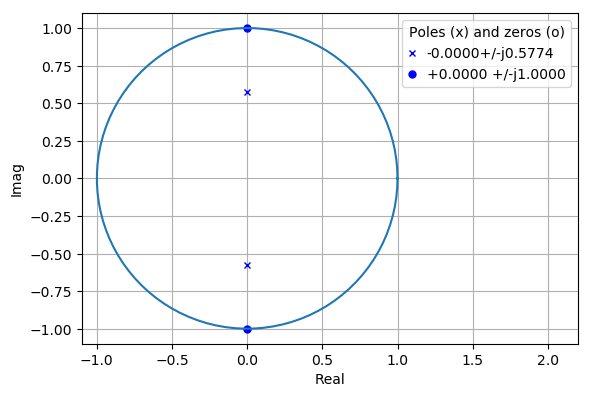

In [5]:
plotPZ(ntf, showlist=True)
a, g, b, c = realizeNTF(ntf, form)

In [6]:
b = np.hstack(( # Use a single feed-in for the input
               np.atleast_1d(b[0]),
               np.zeros((b.shape[0] - 1, ))
             ))
ABCD = stuffABCD(a, g, b, c, form)
print (("ABCD Matrix:\n" + str(ABCD)))

ABCD Matrix:
[[-1.00000000e+00 -2.00000000e+00 -6.66666667e-01  6.66666667e-01]
 [ 1.00000000e+00  1.00000000e+00  0.00000000e+00  1.29198453e-15]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00  0.00000000e+00]]


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_stuffABCD.py:151: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  ABCD[subdiag] = c[0, dly]


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/scipy/signal/filter_design.py:1628: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  "results may be meaningless", BadCoefficients)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:85: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  hold_status = plt.ishold()
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:90: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is dep

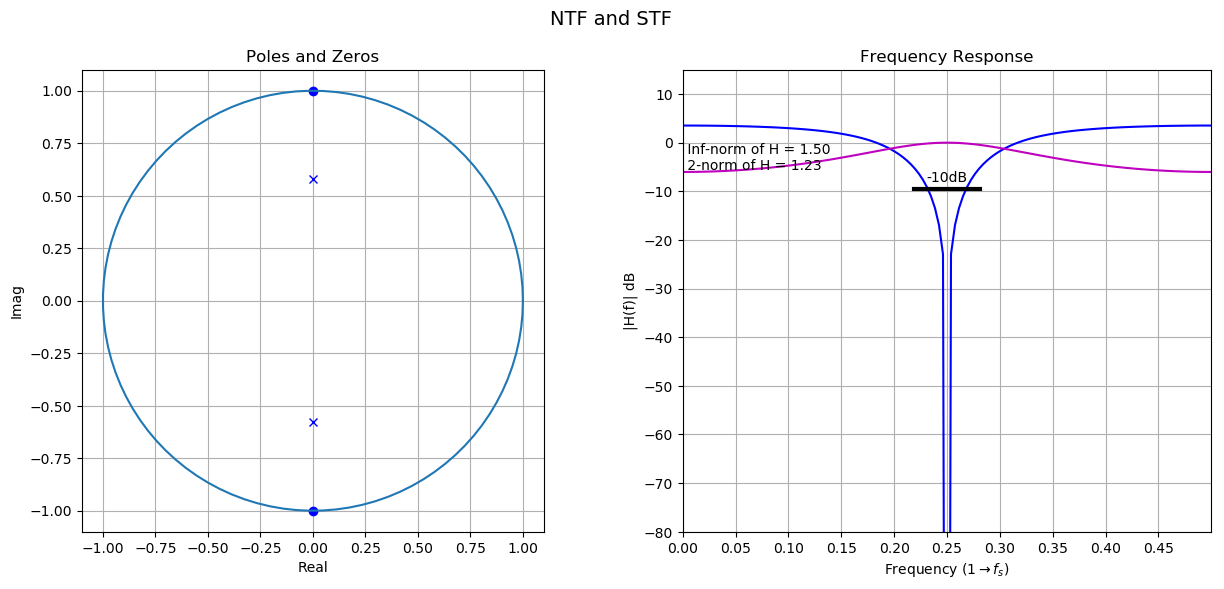

In [8]:
DocumentNTF(ABCD, osr, f0)
f = plt.gcf()
f.set_size_inches((15, 6))

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_simulateDSM.py:214: UserWarning: Using a slow implementation of simulateDSM
Refer to the docs for how to switch to a fast one
  warn('Using a slow implementation of simulateDSM\n' +
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_PlotExampleSpectrum.py:104: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed in 3.0
  mplDeprecation)


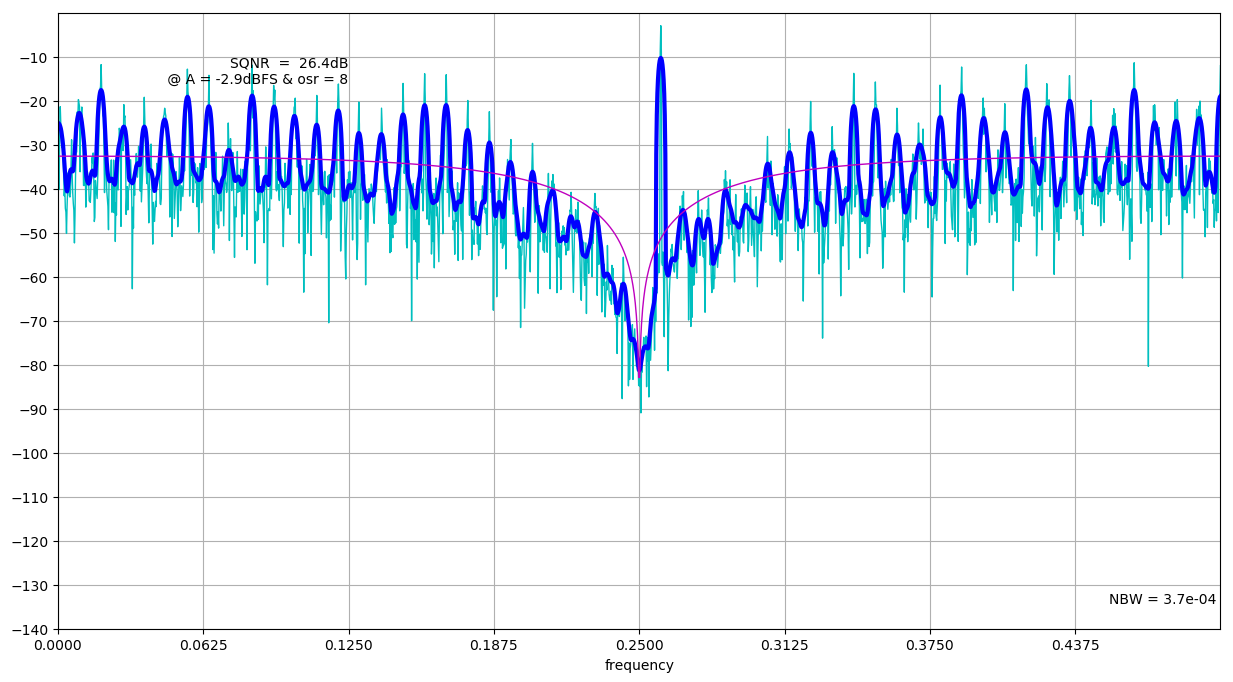

In [9]:
plt.figure(figsize=(15,8))
PlotExampleSpectrum(ntf, M=1, osr=osr, f0=f0)

#ERROR FEEDBACK